# **CLASIFICACIÓN DEL ESTADO FETAL MEDIANTE CARDIOTOCOGRAFÍA Y MACHINE LEARNING.**

### Integrantes: Dylan Luisjuan Rico, Leonardo Alejandro Ambriz Mendoza, Derek Lugo Aguirre, Ricardo Chavez Altamirano

## Objetivo de la práctica

Analizar el tiempo de ejecución y la complejidad computacional de los algoritmos **K-Nearest Neighbors (KNN)** y **Regresión Logística One-vs-Rest (OvR)** desarrollados para el proyecto de cardiotocografía. Se comparan las implementaciones propias con las de `scikit-learn`, utilizando diferentes tamaños de muestra del mismo conjunto de datos.

El análisis se concentra exclusivamente en los tiempos de **entrenamiento (`fit`)** y **predicción (`predict`)**, su crecimiento al aumentar el número de registros y las optimizaciones utilizadas por la biblioteca. No se calculan métricas de clasificación como Accuracy, F1, Recall o AUC, ya que no forman parte del objetivo de esta práctica.

### Organización

1. Carga y preparación de los datos.
2. Implementaciones propias de KNN y Regresión Logística OvR.
3. Medición de tiempos de las implementaciones propias y de `scikit-learn`.
4. Cálculo teórico de la complejidad asintótica.
5. Ajuste empírico, gráficas e interpretación de las optimizaciones.


## **Librerías usadas y Carga de los datos**

In [15]:
import numpy as np
import pandas as pd
from collections import Counter
import time
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from scipy.optimize import curve_fit

print(f"NumPy: {np.__version__}" )
print(f"scikit-learn: {sklearn.__version__}")

NumPy: 2.5.4
scikit-learn: 1.9.1


In [16]:
url = 'https://raw.githubusercontent.com/DylanRico007/fetal-health-classifier-ml/refs/heads/main/data/processed/CTG_clean.csv'
df = pd.read_csv(url)

X = df.drop(columns=["NSP"]).to_numpy(dtype=float)
y = df["NSP"].to_numpy(dtype=int)

print(" Datos del proyecto: ")
print(f"Registros: {X.shape[0]}")
print(f"Características: {X.shape[1]}")
print(f"Clases disponibles: {np.unique(y)}")

 Datos del proyecto: 
Registros: 2126
Características: 21
Clases disponibles: [1 2 3]


## **Muestras para el análisis**


In [17]:
fracciones = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
datasets_por_fraccion = {}

#Se genera una permutacion por clase para conservar la proporción de NSP
rng = np.random.default_rng(42)
indices_por_clase = {
    clase: rng.permutation(np.where(y == clase)[0])
    for clase in np.unique(y)
}

#Division de muestras y de entrenamiento
for frac in fracciones:
    indices = np.concatenate([
        indices_clase[:max(2, round(len(indices_clase) * frac))]
        for indices_clase in indices_por_clase.values()
    ])

    X_sub, y_sub = X[indices], y[indices]
    #Division 80% / 20%
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_sub,
        y_sub,
        test_size=0.20,
        random_state=42,
        stratify=y_sub
    )

    #z Score: los parámetros se obtienen únicamente de X_train
    media = X_train_raw.mean(axis=0)
    desviacion = X_train_raw.std(axis=0)
    desviacion = np.where(desviacion == 0, 1.0, desviacion)

    X_train = (X_train_raw - media) / desviacion
    X_test = (X_test_raw - media) / desviacion

    datasets_por_fraccion[frac] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }

#Tabla con resultados
resumen = pd.DataFrame([
    {
        "Fracción": f"{int(frac * 100)}%",
        "N total": len(datos["y_train"]) + len(datos["y_test"]),
        "N train": len(datos["y_train"]),
        "M test": len(datos["y_test"])
    }
    for frac, datos in datasets_por_fraccion.items()
])

display(resumen)

,Fracción,N total,N train,M test
0,10%,214,171,43
1,20%,425,340,85
2,30%,637,509,128
3,40%,850,680,170
4,50%,1064,851,213
5,60%,1276,1020,256
6,70%,1487,1189,298
7,80%,1701,1360,341
8,90%,1914,1531,383
9,100%,2126,1700,426


## **Implementación de algoritmos**

### KNN del proyecto

In [ ]:
class KNNClassifier:

    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None
    #entrenamiento
    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self
    #calculo de distancias
    def _euclidean_distance(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))
    #prediccion de vecinos
    def _predict_one(self, x):
        distances = np.array([
            self._euclidean_distance(x, x_train)
            for x_train in self.X_train
            ])
        nearest_indices = np.argsort(distances)[:self.n_neighbors]
        nearest_labels = self.y_train[nearest_indices]
        return Counter(nearest_labels.tolist()).most_common(1)[0][0]
    #prediccion
    def predict(self, X):
        return np.array([self._predict_one(x) for x in X])

### KNN: Cálculo de complejidad teórica

Sean:

- **N**: número de registros de entrenamiento.
- **M**: número de registros que se van a clasificar.
- **p**: número de características del conjunto de datos.
- **k**: número de vecinos seleccionados.

**Entrenamiento (`fit`).** La función únicamente asigna las referencias de `X` y `y` a los atributos del objeto. Por ello, el trabajo adicional durante el ajuste es constante:

$$
T_{fit}(N)=O(1)
$$

**Predicción (`predict`).** Para cada registro de prueba se calculan las distancias respecto a los (N) registros de entrenamiento. Cada distancia recorre las (p) características, por lo que el costo de esta operación es (O(Np)). Posteriormente, `np.argsort` ordena los (N) valores de distancia para seleccionar los primeros (k) índices. El ordenamiento utilizado por NumPy tiene un costo de $O(N\log N)$ en el peor caso, al utilizar introsort en sus implementaciones actuales.

Por tanto, para una consulta individual:

$$
O(Np+N\log N)
$$

Para los (M) registros de prueba:

$$
T_{predict}(N,M)=O(M(Np+N\log N))
$$

En este notebook, (p=21) permanece fijo y el tamaño del conjunto de prueba crece proporcionalmente al de entrenamiento. Bajo estas condiciones, el crecimiento conjunto se aproxima a $ O(N^2\log N)$, debido al cálculo de distancias y al ordenamiento completo de estas para cada consulta.

Esta expresión corresponde específicamente al uso de `np.argsort` en nuestra implementación; no debe confundirse con la complejidad de otras estrategias de selección de vecinos.

### KNN implementado de scikit-learn

Se utiliza `KNeighborsClassifier` con los mismos parámetros centrales: cinco vecinos y distancia euclidiana. Se mantiene `algorithm="auto"` para que la biblioteca seleccione la estrategia de búsqueda apropiada para los datos. 

In [19]:
def crear_knn_sklearn():
    return KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean",
        algorithm="auto",
        n_jobs=-1
    )

#Configuracion para los datos del dataset
knn_prueba = crear_knn_sklearn()
datos_completos = datasets_por_fraccion[1.0]
knn_prueba.fit(datos_completos["X_train"], datos_completos["y_train"])

print(f"Características de entrada: {X.shape[1]}")
print("Configuración: algorithm='auto', metric='euclidean'")

Características de entrada: 21
Configuración: algorithm='auto', metric='euclidean'


### KNN de scikit-learn: algoritmo y complejidad

En la documentación de `scikit-learn` se indica que `algorithm="auto"` puede seleccionar la búsqueda por fuerza bruta cuando el número de características (p) es mayor que 15. Nuestro conjunto de datos contiene 21 características, por lo que, para este experimento, se utiliza la estrategia **brute-force**.

Esta estrategia calcula las distancias entre las observaciones de consulta y los registros de entrenamiento mediante las rutinas de cálculo de distancias por pares de la biblioteca.

El costo para (M) consultas, (N) registros de entrenamiento y (p) características es:

$$
T_{predict}(N,M)=O(MNp)
$$

La biblioteca reduce el tiempo práctico mediante rutinas optimizadas para el cálculo de distancias por pares, procedimientos de selección de los (k) vecinos y ejecución paralela cuando se utiliza `n_jobs=-1`.

A diferencia de esta implementación, el KNN desarrollado en el proyecto ordena completamente las distancias de cada consulta mediante `np.argsort`, lo que agrega el término $N\log N$ al costo de predicción.

En cuanto al entrenamiento, nuestra implementación propia únicamente almacena las referencias de los datos, por lo que su costo adicional es constante: $O(1)$.

En `scikit-learn`, el entrenamiento realiza validaciones y preparación de los datos antes de almacenarlos. Por ello, su costo depende del tamaño del conjunto de entrada y puede aproximarse por $O(Np)$. Como el número de características se mantiene fijo en este experimento (p=21), el crecimiento respecto al número de registros es lineal: $O(N)$.

Esta diferencia se debe a que la implementación propia únicamente asigna las referencias de los datos, mientras que la biblioteca realiza operaciones adicionales de validación y preparación.

### Regresión Logística: Implementación del proyecto

La clase de Regresión Logística utilizada en el proyecto corresponde a un clasificador binario. Para adaptarla a las tres categorías de NSP se utiliza la estrategia **One-vs-Rest (OvR)**, mediante la cual se entrenan tres clasificadores binarios independientes. Cada clasificador se especializa en identificar una clase frente a las dos restantes.

Durante la predicción, cada modelo calcula un puntaje mediante la función sigmoide. La clase final se determina seleccionando aquella cuyo clasificador obtiene el mayor puntaje.

Debido a ello, la implementación está compuesta por dos clases: una primera clase que realiza la clasificación binaria mediante regresión logística y una segunda clase que coordina el entrenamiento y la predicción de los tres clasificadores independientes mediante la estrategia OvR.

In [20]:
class LogisticRegression:

    def __init__(self, learning_rate=0.1, n_iterations=2000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.biases = None

    #calculo de sigmoide
    def sigmoide(self, z):
        return 1 / (1 + np.exp(-z))
    #prediccion de prob
    def predict_proba(self, X):
        return self.sigmoide(X.dot(self.weights) + self.biases)
    #clasificacion de clase
    def predict(self, X, threshold=0.3): 
        return (self.predict_proba(X) >= threshold).astype(int)
    #loss
    def compute_cost(self, X, y):
        eps = 1e-15
        p = np.clip(self.predict_proba(X), eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    #descenso de gradiente
    def compute_gradients(self, X, y):
        n_samples = X.shape[0]
        errors = self.predict_proba(X) - y
        dw = (1 / n_samples) * X.T.dot(errors)
        db = (1 / n_samples) * np.sum(errors)
        return dw, db
    #entrenamiento
    def fit(self, X, y):
        n_features = X.shape[1]
        self.weights = np.zeros(n_features)
        self.biases = 0.0

        for _ in range(self.n_iterations):
            dw, db = self.compute_gradients(X, y)
            self.weights -= self.learning_rate * dw
            self.biases -= self.learning_rate * db
        return self


 #Combina tres clasificadores binarios de Regresión Logística
class LogisticRegressionOvR:
   
    def __init__(self, learning_rate=0.1, n_iterations=2000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.classes_ = None
        self.models_ = []

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = [] #guarda los modelos
        #calculo de cada clase para cada modelo
        for clase in self.classes_:
            y_binario = (y == clase).astype(int)
            modelo = LogisticRegression(
                learning_rate=self.learning_rate,
                n_iterations=self.n_iterations
            )
            modelo.fit(X, y_binario)
            self.models_.append(modelo)
        return self
    #agrupa los 3 puntjaes de la prediccion y toma el mas alto
    def predict(self, X):
        puntajes = np.column_stack([
            modelo.predict_proba(X) for modelo in self.models_
        ])
        return self.classes_[np.argmax(puntajes, axis=1)]

### Regresión Logística OvR del proyecto: cálculo de complejidad teórica

Sean:

- **N**: número de registros de entrenamiento.
- **M**: número de registros de prueba.
- **p**: número de características.
- **C**: número de clases.
- **I**: número de iteraciones del descenso de gradiente.

En el **entrenamiento**, cada iteración del clasificador binario calcula la combinación lineal $ Xw+b $ y los gradientes correspondientes. Ambas operaciones recorren la matriz de datos y tienen un costo proporcional a (Np). Al utilizar la estrategia OvR, este proceso se repite para cada una de las (C) clases. Por lo tanto:

$$
T_{fit}(N)=O(CINp)
$$

Debido a que (C), (I) y (p) se mantienen fijos en el experimento, el crecimiento respecto al número de registros es lineal:

$$
O(N)
$$

En la **predicción**, cada uno de los tres clasificadores calcula un producto entre las observaciones de prueba (M) y sus respectivos pesos (p). La selección del mayor puntaje entre las clases agrega un costo proporcional a (CM). Por lo tanto:

$$
T_{predict}(M)=O(CMp)
$$

Con (C = 3) y ( p = 21) fijos, la predicción crece linealmente con el número de registros de prueba:

$$
O(M)
$$

### Regresión Logistica OvR de scikit-learn

Comparando el mismo esquema multiclase, se usa `OneVsRestClassifier` con `LogisticRegression` y el solver `lbfgs`, manteniendo `max_iter=2000`, como en el notebook de modelado. A diferencia de nuestra clase del proyecto, `scikit-learn` aplica regularización L2 por defecto.

In [ ]:
def crear_logistica_sklearn():
    base = SklearnLogisticRegression(
        solver="lbfgs", #optimizacion para iteraciones dinamicas
        max_iter=2000,
        random_state=42 #aleatoriedad fijada para la función
    )
    return OneVsRestClassifier(base)

### Regresión Logística de scikit-learn: optimización y complejidad

`OneVsRestClassifier` ajusta un clasificador binario por cada clase. En `LogisticRegression`, el solver seleccionado es **L-BFGS**, un método cuasi-Newton de memoria limitada. El número de iteraciones depende del criterio de convergencia (`tol`) y está limitado por `max_iter`; por ello, no existe un número fijo de iteraciones equivalente al utilizado en nuestra implementación propia.

Si $I_{LBFGS}$ representa el número de iteraciones utilizadas por cada clasificador, el costo dominante del ajuste puede expresarse de manera aproximada como:

$$
T_{fit}(N)=O(CI_{LBFGS}Np)
$$

El número efectivo de iteraciones debe interpretarse junto con el tiempo medido. En el intervalo de tamaños de datos de esta práctica también se ajustará una función lineal para describir el crecimiento observado, sin presentarla como una demostración universal del comportamiento del solver.

En la predicción, cada modelo calcula los puntajes correspondientes a \(M\) registros y (p) características:

$$
T_{predict}(M)=O(CMp)
$$

Por lo tanto, con un número fijo de clases y características, el costo de predicción es lineal respecto a (M).

Las ventajas prácticas de `scikit-learn` provienen del solver L-BFGS, del uso de operaciones numéricas optimizadas y de sus rutinas de validación y manejo de matrices. Estas optimizaciones reducen el tiempo observado, pero no eliminan el costo computacional de procesar las observaciones.

### Funcion para medir los tiempos

Se mide por separado `fit` y  `predict`, usando 7 repeticiones por tamaño de muestra. Primero se ejecuta una corrida de calentamiento antes de cronometrar. Se presenta el promedio y la mediana en milisegundos, usando esta última para la graficación y ajustes.

In [ ]:
REPETICIONES = 7

#funcion para tiempos
def medir_tiempos_modelo(crear_modelo_fn, datos, repeticiones=REPETICIONES):
    X_train = datos["X_train"]
    y_train = datos["y_train"]
    X_test = datos["X_test"]

    #Calentamiento
    #no se incluye en los tiempos reportados
    modelo = crear_modelo_fn()
    modelo.fit(X_train, y_train)
    modelo.predict(X_test)

    tiempos_fit = []
    tiempos_predict = []
    #Bucle para la medición del tiempo de los modelos
    for _ in range(repeticiones):
        modelo = crear_modelo_fn()

        inicio = time.perf_counter()
        modelo.fit(X_train, y_train)
        tiempos_fit.append((time.perf_counter() - inicio) * 1000)

        inicio = time.perf_counter()
        modelo.predict(X_test)
        tiempos_predict.append((time.perf_counter() - inicio) * 1000)

    return {
        "Fit promedio (ms)": np.mean(tiempos_fit),
        "Fit mediana (ms)": np.median(tiempos_fit),
        "Predict promedio (ms)": np.mean(tiempos_predict),
        "Predict mediana (ms)": np.median(tiempos_predict)
    }

## **Medición de tiempos**
### Implementaciones propias y de biblioteca

Se usan los mismos tamaños de muestra, particiones y datos estandarizados para los 4 casos. Los parametros principales se mantienen iguales al proyecto: KNN con 5 vecinos y Regresion Logistica OvR con 3 clasificadores y 2000 iteraciones.

In [ ]:
#modelos agrupados para ejecutar en el bucle, cada uno con sus requerimientos
modelos = {
    "KNN propio": lambda: KNNClassifier(n_neighbors=5),
    "KNN scikit-learn": crear_knn_sklearn,
    "Logística OvR propia": lambda: LogisticRegressionOvR(
        learning_rate=0.1, n_iterations=2000
    ),
    "Logística OvR scikit-learn": crear_logistica_sklearn
}

resultados = []
#Procesamiento de tiempos de cada modelo y agrupamiento en una lista para mostrar en un dataframe
for frac, datos in datasets_por_fraccion.items():
    for nombre, crear_modelo in modelos.items():
        medicion = medir_tiempos_modelo(crear_modelo, datos)
        resultados.append({
            "Fracción": f"{int(frac * 100)}%",
            "Modelo": nombre,
            "N train": len(datos["y_train"]),
            "M test": len(datos["y_test"]),
            **medicion
        })

resultados_tiempos = pd.DataFrame(resultados)
display(resultados_tiempos.round(4))

,Fracción,Modelo,N train,M test,Fit promedio (ms),Fit mediana (ms),Predict promedio (ms),Predict mediana (ms)
0,10%,KNN propio,171,43,0.0010,0.0010,31.7440,31.9714
1,10%,KNN scikit-learn,171,43,0.7752,0.6999,4.1368,3.9090
2,10%,Logística OvR propia,171,43,117.2494,115.8238,0.0580,0.0542
3,10%,Logística OvR scikit-learn,171,43,23.3065,22.4092,0.5679,0.5341
4,20%,KNN propio,340,85,0.0005,0.0005,107.5668,104.6750
5,20%,KNN scikit-learn,340,85,0.6866,0.6542,5.1220,5.0859
6,20%,Logística OvR propia,340,85,133.3812,129.0615,0.0541,0.0495
7,20%,Logística OvR scikit-learn,340,85,25.6913,25.9971,0.5649,0.5567
8,30%,KNN propio,509,128,0.0007,0.0006,268.4376,268.4760
9,30%,KNN scikit-learn,509,128,0.7107,0.6858,5.0944,5.1160


### Resumen de tiempos

La siguiente tabla permite comparar de manera más clara los tiempos de entrenamiento y predicción de cada modelo.

In [ ]:
resumen_tiempos = resultados_tiempos.pivot_table(
    index=["Fracción", "N train", "M test"],
    columns="Modelo",
    values=["Fit mediana (ms)", "Predict mediana (ms)"]
)
#fraccion inicial y final juntas para comparacion
display(resumen_tiempos.round(4))

Fit mediana (ms)                   \
Modelo                        KNN propio KNN scikit-learn   
Fracción N train M test                                     
10%      171     43               0.0010           0.6999   
100%     1700    426              0.0010           0.8375   
20%      340     85               0.0005           0.6542   
30%      509     128              0.0006           0.6858   
40%      680     170              0.0011           0.6921   
50%      851     213              0.0010           0.7603   
60%      1020    256              0.0010           0.7401   
70%      1189    298              0.0005           0.7976   
80%      1360    341              0.0005           0.7814   
90%      1531    383              0.0010           0.8897   

                                                                         \
Modelo                  Logística OvR propia Logística OvR scikit-learn   
Fracción N train M test                                                   
10%      171     43                 115.8238                    22.4092   
100%     1700    426                320.7521                    42.7461   
20%      340     85                 129.0615                    25.9971   
30%      509     128                155.1497                    27.7853   
40%      680     170                180.9358                    28.8144   
50%      851     213                203.4343                    29.9500   
60%      1020    256                236.7981                    32.1621   
70%      1189    298                238.9497                    34.3481   
80%      1360    341                251.1156                    33.3598   
90%      1531    383                318.9057                    35.0461   

                        Predict mediana (ms)                   \
Modelo                            KNN propio KNN scikit-learn   
Fracción N train M test                                         
10%      171     43                  31.9714           3.9090   
100%     1700    426               2926.5604           3.7136   
20%      340     85                 104.6750           5.0859   
30%      509     128                268.4760           5.1160   
40%      680     170                417.8544           5.9521   
50%      851     213                692.6658           7.2958   
60%      1020    256                993.6894           6.9317   
70%      1189    298               1409.4541          10.3628   
80%      1360    341               1752.6804           3.6272   
90%      1531    383               2219.9825           3.5941   

                                                                         
Modelo                  Logística OvR propia Logística OvR scikit-learn  
Fracción N train M test                                                  
10%      171     43                   0.0542                     0.5341  
100%     1700    426                  0.0819                     0.6229  
20%      340     85                   0.0495                     0.5567  
30%      509     128                  0.0627                     0.5415  
40%      680     170                  0.0599                     0.5066  
50%      851     213                  0.0653                     0.5137  
60%      1020    256                  0.0671                     0.7039  
70%      1189    298                  0.0721                     0.5272  
80%      1360    341                  0.0708                     0.5690  
90%      1531    383                  0.0851                     0.5624

## **Ajuste empirico de las funciones**

Se ajustan funciones sencillas a las medianas medidas. Las formas utilizadas corresponden al análisis teórico anterior:

| Modelo y fase | Función de referencia |
|---|---|
| KNN propio – `fit` | Constante, $O(1)$ |
| KNN propio – `predict` | $M N log N$, por el ordenamiento completo de distancias |
| KNN scikit-learn – `fit` | Lineal aproximada en (N), asociada a validación y preparación de datos |
| KNN scikit-learn – `predict` | ($M N$), con ($p$) fijo y búsqueda por fuerza bruta |
| Regresión Logística OvR propia – `fit` | Lineal en $(N$), con ($C$), ($I$) y ($p$) fijos |
| Regresión Logística OvR propia – `predict` | Lineal en ($M$) |
| Regresión Logística OvR scikit-learn – `fit` | Ajuste lineal empírico en ($N$) para el rango medido |
| Regresión Logística OvR scikit-learn – `predict` | Lineal en ($M$) |

El ajuste empírico describe el comportamiento de los tiempos dentro del intervalo de tamaños probado. Un valor bajo de $R^2$ indica que los tiempos obtenidos no siguen claramente la función propuesta en este intervalo. Por ello, no se debe forzar una conclusión a partir de una curva que presenta un ajuste poco representativo. Como nota al KNN propio en su predicción, $O(M(Np+N\log N))$ se convierte en $M N log N$ al suponer que p es fijo pues si (N) crece mucho, al final $NlogN$ pesa mas que $Np$ por lo cual se descarta y queda $MNlogN$ aplicado con lo ya supuesto, la expresion completa sigue siendo $O(M(Np+N\log N))$.

In [25]:
#Funciones teóricas/empíricas utilizadas para el ajuste.
def modelo_constante(N, c):
    return np.full_like(np.asarray(N, dtype=float), c, dtype=float)


def modelo_lineal(N, a, b):
    return a * np.asarray(N, dtype=float) + b


def modelo_knn_propio(x, a, b):
    N_train, M_test = x
    return a * M_test * N_train * np.log(N_train) + b


def modelo_knn_sklearn(x, a, b):
    N_train, M_test = x
    return a * M_test * N_train + b


def calcular_r2(y_real, y_estimado):
    ss_res = np.sum((y_real - y_estimado) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1.0 if ss_tot == 0 else 1 - ss_res / ss_tot


N_train = resultados_tiempos[
    resultados_tiempos["Modelo"] == "KNN propio"
]["N train"].to_numpy(dtype=float)
M_test = resultados_tiempos[
    resultados_tiempos["Modelo"] == "KNN propio"
]["M test"].to_numpy(dtype=float)

#
def obtener_tiempos(modelo, columna):
    tabla = resultados_tiempos[resultados_tiempos["Modelo"] == modelo]
    return tabla[columna].to_numpy(dtype=float)


t_knn_fit = obtener_tiempos("KNN propio", "Fit mediana (ms)")
t_knn_predict = obtener_tiempos("KNN propio", "Predict mediana (ms)")
t_knn_sk_fit = obtener_tiempos("KNN scikit-learn", "Fit mediana (ms)")
t_knn_sk_predict = obtener_tiempos("KNN scikit-learn", "Predict mediana (ms)")

t_lr_fit = obtener_tiempos("Logística OvR propia", "Fit mediana (ms)")
t_lr_predict = obtener_tiempos("Logística OvR propia", "Predict mediana (ms)")
t_lr_sk_fit = obtener_tiempos("Logística OvR scikit-learn", "Fit mediana (ms)")
t_lr_sk_predict = obtener_tiempos("Logística OvR scikit-learn", "Predict mediana (ms)")

#Ajustes mediante curve_fit
p_knn_fit, _ = curve_fit(
    modelo_constante, N_train, t_knn_fit,
    p0=[np.median(t_knn_fit)], maxfev=20000
)
p_knn_predict, _ = curve_fit(
    modelo_knn_propio, (N_train, M_test), t_knn_predict,
    p0=[t_knn_predict[-1] / (M_test[-1] * N_train[-1] * np.log(N_train[-1])), 0.0],
    maxfev=20000
)
p_knn_sk_fit, _ = curve_fit(
    modelo_lineal, N_train, t_knn_sk_fit,
    p0=[(t_knn_sk_fit[-1] - t_knn_sk_fit[0]) / (N_train[-1] - N_train[0]), t_knn_sk_fit[0]],
    maxfev=20000
)
p_knn_sk_predict, _ = curve_fit(
    modelo_knn_sklearn, (N_train, M_test), t_knn_sk_predict,
    p0=[t_knn_sk_predict[-1] / (M_test[-1] * N_train[-1]), 0.0],
    maxfev=20000
)
p_lr_fit, _ = curve_fit(
    modelo_lineal, N_train, t_lr_fit,
    p0=[(t_lr_fit[-1] - t_lr_fit[0]) / (N_train[-1] - N_train[0]), t_lr_fit[0]],
    maxfev=20000
)
p_lr_predict, _ = curve_fit(
    modelo_lineal, M_test, t_lr_predict,
    p0=[t_lr_predict[-1] / M_test[-1], 0.0], maxfev=20000
)
p_lr_sk_fit, _ = curve_fit(
    modelo_lineal, N_train, t_lr_sk_fit,
    p0=[(t_lr_sk_fit[-1] - t_lr_sk_fit[0]) / (N_train[-1] - N_train[0]), t_lr_sk_fit[0]],
    maxfev=20000
)
p_lr_sk_predict, _ = curve_fit(
    modelo_lineal, M_test, t_lr_sk_predict,
    p0=[t_lr_sk_predict[-1] / M_test[-1], 0.0], maxfev=20000
)

#Coeficientes de determinacion sobre las observaciones medida
r2 = {
    "KNN propio fit": calcular_r2(t_knn_fit, modelo_constante(N_train, *p_knn_fit)),
    "KNN propio predict": calcular_r2(t_knn_predict, modelo_knn_propio((N_train, M_test), *p_knn_predict)),
    "KNN scikit fit": calcular_r2(t_knn_sk_fit, modelo_lineal(N_train, *p_knn_sk_fit)),
    "KNN scikit predict": calcular_r2(t_knn_sk_predict, modelo_knn_sklearn((N_train, M_test), *p_knn_sk_predict)),
    "Logística propia fit": calcular_r2(t_lr_fit, modelo_lineal(N_train, *p_lr_fit)),
    "Logística propia predict": calcular_r2(t_lr_predict, modelo_lineal(M_test, *p_lr_predict)),
    "Logística scikit fit": calcular_r2(t_lr_sk_fit, modelo_lineal(N_train, *p_lr_sk_fit)),
    "Logística scikit predict": calcular_r2(t_lr_sk_predict, modelo_lineal(M_test, *p_lr_sk_predict))
}

print("--- R² de los ajustes empíricos ---")
for nombre, valor in r2.items():
    print(f"{nombre:28s}: {valor:.4f}")

--- R² de los ajustes empíricos ---
KNN propio fit              : 0.0000
KNN propio predict          : 0.9982
KNN scikit fit              : 0.8189
KNN scikit predict          : 0.0445
Logística propia fit        : 0.9729
Logística propia predict    : 0.8926
Logística scikit fit        : 0.9070
Logística scikit predict    : 0.1453


## **Gráficas de KNN hecho y de scikit-learn**

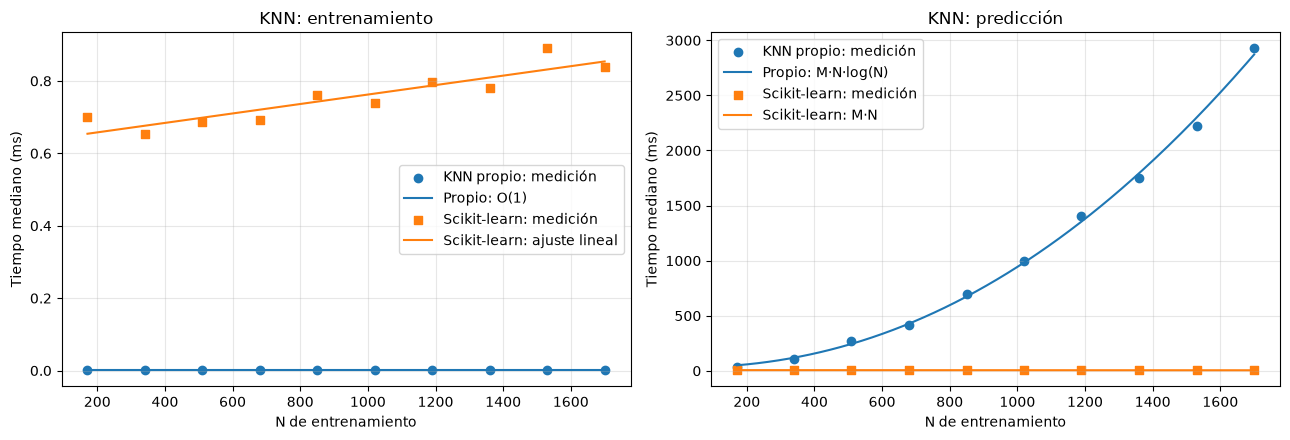

In [26]:
N_suave = np.linspace(N_train.min(), N_train.max(), 200)
M_suave = (M_test / N_train).mean() * N_suave

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

#Entrenamiento KNN
axes[0].scatter(N_train, t_knn_fit, label="KNN propio: medición")
axes[0].plot(N_suave, modelo_constante(N_suave, *p_knn_fit), label="Propio: O(1)")
axes[0].scatter(N_train, t_knn_sk_fit, marker="s", label="Scikit-learn: medición")
axes[0].plot(N_suave, modelo_lineal(N_suave, *p_knn_sk_fit), label="Scikit-learn: ajuste lineal")
axes[0].set_title("KNN: entrenamiento")
axes[0].set_xlabel("N de entrenamiento")
axes[0].set_ylabel("Tiempo mediano (ms)")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Prediccion KNN
axes[1].scatter(N_train, t_knn_predict, label="KNN propio: medición")
axes[1].plot(N_suave, modelo_knn_propio((N_suave, M_suave), *p_knn_predict), label="Propio: M·N·log(N)")
axes[1].scatter(N_train, t_knn_sk_predict, marker="s", label="Scikit-learn: medición")
axes[1].plot(N_suave, modelo_knn_sklearn((N_suave, M_suave), *p_knn_sk_predict), label="Scikit-learn: M·N")
axes[1].set_title("KNN: predicción")
axes[1].set_xlabel("N de entrenamiento")
axes[1].set_ylabel("Tiempo mediano (ms)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## **Gráficas: Regresion Logistica OvR hecha y de scikit-learn**

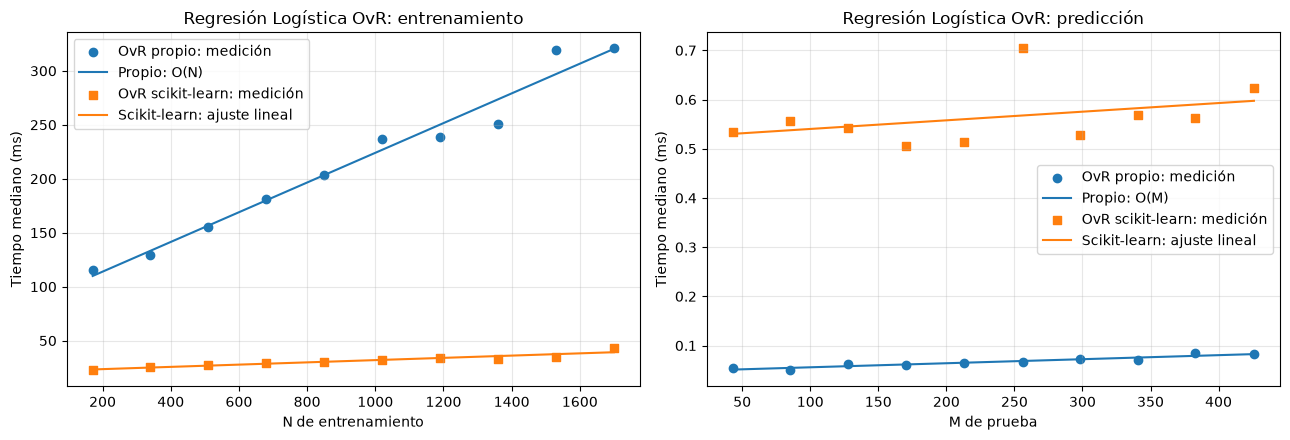

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

#Entrenamiento de Regresion Logística
axes[0].scatter(N_train, t_lr_fit, label="OvR propio: medición")
axes[0].plot(N_suave, modelo_lineal(N_suave, *p_lr_fit), label="Propio: O(N)")
axes[0].scatter(N_train, t_lr_sk_fit, marker="s", label="OvR scikit-learn: medición")
axes[0].plot(N_suave, modelo_lineal(N_suave, *p_lr_sk_fit), label="Scikit-learn: ajuste lineal")
axes[0].set_title("Regresión Logística OvR: entrenamiento")
axes[0].set_xlabel("N de entrenamiento")
axes[0].set_ylabel("Tiempo mediano (ms)")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Prediccion de Regresion Logistica
M_suave = np.linspace(M_test.min(), M_test.max(), 200)
axes[1].scatter(M_test, t_lr_predict, label="OvR propio: medición")
axes[1].plot(M_suave, modelo_lineal(M_suave, *p_lr_predict), label="Propio: O(M)")
axes[1].scatter(M_test, t_lr_sk_predict, marker="s", label="OvR scikit-learn: medición")
axes[1].plot(M_suave, modelo_lineal(M_suave, *p_lr_sk_predict), label="Scikit-learn: ajuste lineal")
axes[1].set_title("Regresión Logística OvR: predicción")
axes[1].set_xlabel("M de prueba")
axes[1].set_ylabel("Tiempo mediano (ms)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## **Interpretación de resultados y optimizaciones**


### KNN


Los resultados experimentales muestran diferencias en el tiempo de entrenamiento y predicción entre las implementaciones propias y las de scikit-learn. En KNN, la implementación propia presenta un tiempo de entrenamiento prácticamente constante, ya que únicamente almacena las referencias a los datos. Sin embargo, su predicción requiere calcular las distancias respecto a las observaciones de entrenamiento y seleccionar los cinco vecinos más cercanos, lo que incrementa considerablemente el tiempo conforme aumenta el tamaño del conjunto. Por su parte, scikit-learn aprovecha rutinas numéricas optimizadas, la selección de vecinos y el paralelismo para reducir el tiempo de ejecución.


### Regresión Logística OvR


En la Regresión Logística OvR, la implementación propia presenta un crecimiento del tiempo de entrenamiento asociado a las 2000 iteraciones ejecutadas para cada uno de los tres clasificadores. En contraste, scikit-learn utiliza el método L-BFGS, que ajusta el proceso de optimización mediante criterios de convergencia. No obstante, el rendimiento de ambas implementaciones depende del tamaño de los datos, de las operaciones realizadas en cada iteración y de las condiciones de ejecución.


### Alcance del ajuste empírico


Los valores de $R^2$ permiten determinar qué tan bien las curvas seleccionadas representan los tiempos medidos dentro del intervalo experimental. Los valores altos indican que existe un ajuste adecuado entre la curva y las mediciones observadas, pero no demuestran por sí mismos que la complejidad asintótica teórica sea correcta. En cambio, los valores bajos reflejan que la curva seleccionada no describe adecuadamente la variación de los tiempos en el intervalo analizado. Particularmente, el valor $R^2 = 0$ obtenido en el entrenamiento de KNN propio se explica porque sus tiempos son prácticamente constantes, por lo que no existe una variación significativa que la curva pueda representar.

Por lo tanto, la complejidad temporal de cada algoritmo debe justificarse principalmente a partir de las operaciones que realiza su implementación y de su comportamiento teórico. Los valores de $R^2$ y las gráficas funcionan como evidencia experimental complementaria, útil para analizar el comportamiento observado, pero no como una demostración de la complejidad asintótica.

Finalmente, es importante considerar que los tiempos registrados pueden variar según el procesador, la memoria disponible, las versiones de Python y de las bibliotecas utilizadas, la carga del sistema y el paralelismo. Por esta razón, las mediciones deben interpretarse dentro de las condiciones y los tamaños de datos evaluados, sin generalizar los resultados experimentales a todos los escenarios de ejecución.



## **Conclusiones**

Se analizó el costo temporal de las implementaciones propias de KNN y Regresión Logística OvR, y se compararon con las versiones de `scikit-learn`. El análisis teórico permite explicar dónde se concentra el trabajo de cada algoritmo: en KNN, durante la búsqueda de vecinos para cada observación; en Regresión Logística, durante las iteraciones necesarias para ajustar los tres clasificadores binarios.

La comparación con la biblioteca debe interpretarse considerando las optimizaciones realmente utilizadas. Para KNN, las 21 características hacen que `algorithm="auto"` seleccione la búsqueda por fuerza bruta, por lo que no corresponde atribuir los resultados a KD-Tree o Ball-Tree. Para Regresión Logística, L-BFGS modifica el proceso de optimización y el número de iteraciones, mientras que la predicción conserva un costo lineal respecto al número de observaciones consultadas cuando las características y las clases se mantienen fijas.

Los tiempos medidos corresponden al entorno en el que se ejecuta este notebook. Las curvas ajustadas permiten comparar el comportamiento observado, pero no sustituyen el análisis asintótico derivado de las operaciones de cada implementación.

## **Referencias**
- Campos, D., y Bernardes, J. (2000). Cardiotocography [Conjunto de
datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C51S4N
- NumPy Developers. (2026). numpy.argsort (Versión 2.5) [Documentación
de software]. https://numpy.org/doc/stable/reference/generated/numpy.argsort.html
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Gri-
sel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V.,
Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot,
M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in
Python. Journal of Machine Learning Research, 12, 2825–2830.
https://jmlr.org
- Scikit-learn Developers. (2026a). LogisticRegression (Versión 1.9.1)
[Documentación de software]. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- Scikit-learn Developers. (2026b). Nearest Neighbors (Versión 1.9.1)
[Documentación de software]. https://scikit-learn.org/stable/modules/neighbors.html
